In [1]:
import xarray as xr
import numpy as np
import xesmf as xe
from regional_mom6 import regridding as rgd

In [2]:
river_nutrients = xr.open_dataset("/glade/work/mlevy/cesm_inputdata/work/river_nutrients.GNEWS_GNM.glofas.20250916.nc")
river_nutrients = river_nutrients.assign_coords(
    lon=((river_nutrients.lon + 360) % 360)
)
river_nutrients
rn_sorted = river_nutrients.sortby("lon")


In [3]:
mapping_file = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/gustavo_glorys/stuff_for_final_run/runoff_mapping/new_glofas/glofas_v4_tasman_nnsm.nc")
mapping_file

<xarray.Dataset>
Dimensions:        (n_a: 21600000, nv_a: 4, src_grid_rank: 2, nj_a: 3000,
                    ni_a: 7200, n_b: 3430, nv_b: 4, dst_grid_rank: 2, nj_b: 49,
                    ni_b: 70, n_s: 3075665)
Coordinates:
  * nj_a           (nj_a) int32 1 2 3 4 5 6 7 ... 2995 2996 2997 2998 2999 3000
  * ni_a           (ni_a) int32 1 2 3 4 5 6 7 ... 7195 7196 7197 7198 7199 7200
  * nj_b           (nj_b) int32 1 2 3 4 5 6 7 8 9 ... 41 42 43 44 45 46 47 48 49
  * ni_b           (ni_b) int32 1 2 3 4 5 6 7 8 9 ... 62 63 64 65 66 67 68 69 70
Dimensions without coordinates: n_a, nv_a, src_grid_rank, n_b, nv_b,
                                dst_grid_rank, n_s
Data variables: (12/19)
    xc_a           (n_a) float64 ...
    yc_a           (n_a) float64 ...
    xv_a           (n_a, nv_a) float64 ...
    yv_a           (n_a, nv_a) float64 ...
    mask_a         (n_a) int32 ...
    area_a         (n_a) float64 ...
    ...             ...
    area_b         (n_b) float64 ...
    frac_b         (n_b) float64 ...
    dst_grid_dims  (dst_grid_rank) int32 ...
    S              (n_s) float64 ...
    col            (n_s) int32 ...
    row            (n_s) int32 ...
Attributes:
    title:        mom6_bathy mapping generation
    history:      generated by mom6_bathy
    conventions:  NCAR-CCSM

In [4]:
# Grids
glofas_grid = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/gustavo_glorys/stuff_for_final_run/runoff_mapping/new_glofas/GLOFAS_grid_v4.nc")
tasman_grid_t_points = xr.open_dataset("/glade/derecho/scratch/manishrv/croc_input/tasman.glofas.1/ocnice/ocean_topog_tasman_c1af93.nc")
tasman_grid_t_points["lon"] = tasman_grid_t_points.x
tasman_grid_t_points["lat"] = tasman_grid_t_points.y
glofas_grid_t_points = rgd.get_hgrid_arakawa_c_points(glofas_grid, "t")
glofas_grid_t_points["lon"] = glofas_grid_t_points["tlon"]
glofas_grid_t_points["lon"].attrs["units"] = "degrees_east"
glofas_grid_t_points["lat"] = glofas_grid_t_points["tlat"]

In [5]:
tasman_grid_t_points.lat.values

array([[-43.95, -43.95, -43.95, ..., -43.95, -43.95, -43.95],
       [-43.85, -43.85, -43.85, ..., -43.85, -43.85, -43.85],
       [-43.75, -43.75, -43.75, ..., -43.75, -43.75, -43.75],
       ...,
       [-39.35, -39.35, -39.35, ..., -39.35, -39.35, -39.35],
       [-39.25, -39.25, -39.25, ..., -39.25, -39.25, -39.25],
       [-39.15, -39.15, -39.15, ..., -39.15, -39.15, -39.15]])

In [6]:
# Convert Units
vars = ["din_riv_flux","dip_riv_flux","don_riv_flux","don_riv_flux","dsi_riv_flux","dsi_riv_flux","dic_riv_flux","alk_riv_flux","doc_riv_flux"]
conversion_factor = 0.01 # mmol -> nmol
for v in vars:
    rn_sorted[v] = rn_sorted[v] * conversion_factor
    rn_sorted[v].attrs["units"] = "mmol/cm^2/s"

In [7]:
# Remap
regridder = xe.Regridder(glofas_grid_t_points, tasman_grid_t_points,method = "bilinear", reuse_weights=True, filename = "/glade/u/home/manishrv/documents/croc/dev/gustavo_glorys/stuff_for_final_run/runoff_mapping/new_glofas/glofas_v4_tasman_nnsm.nc")
regridder


xESMF Regridder 
Regridding algorithm:       bilinear 
Weight filename:            /glade/u/home/manishrv/documents/croc/dev/gustavo_glorys/stuff_for_final_run/runoff_mapping/new_glofas/glofas_v4_tasman_nnsm.nc 
Reuse pre-computed weights? True 
Input grid shape:           (3000, 7200) 
Output grid shape:          (49, 70) 
Periodic in longitude?      False

In [27]:
# Remap
regridder_nn = xe.Regridder(glofas_grid_t_points, tasman_grid_t_points,method = "bilinear", reuse_weights=True, filename = "/glade/u/home/manishrv/documents/croc/dev/gustavo_glorys/stuff_for_final_run/runoff_mapping/new_glofas/glofas_v4_tasman_nnsm.nc")
regridder_nn


xESMF Regridder 
Regridding algorithm:       bilinear 
Weight filename:            /glade/u/home/manishrv/documents/croc/dev/gustavo_glorys/stuff_for_final_run/runoff_mapping/new_glofas/glofas_v4_tasman_nnsm.nc 
Reuse pre-computed weights? True 
Input grid shape:           (3000, 7200) 
Output grid shape:          (99, 141) 
Periodic in longitude?      False

In [8]:
# Remap 
river_nutrients_remapped = regridder(rn_sorted)
river_nutrients_remapped

<xarray.Dataset>
Dimensions:                       (ny: 49, nx: 70, nv: 4, time: 21)
Coordinates:
  * time                          (time) object 1900-07-01 12:00:00 ... 2000-...
Dimensions without coordinates: ny, nx, nv
Data variables: (12/28)
    xc                            (ny, nx) float64 77.05 83.88 ... 88.73 80.96
    yc                            (ny, nx) float64 -23.46 -25.53 ... -21.34
    xv                            (nv, ny, nx) float64 77.04 83.87 ... 80.95
    yv                            (nv, ny, nx) float64 -23.47 -25.55 ... -21.32
    area                          (ny, nx) float64 1.201e+07 ... 1.292e+07
    LAT                           (ny, nx) float64 -23.46 -25.53 ... -21.34
    ...                            ...
    don_riv_flux                  (time, ny, nx) float64 0.0 0.0 0.0 ... 0.0 0.0
    pn_riv_flux                   (time, ny, nx) float64 0.0 0.0 0.0 ... 0.0 0.0
    dip_riv_flux                  (time, ny, nx) float64 0.0 0.0 0.0 ... 0.0 0.0
    dop_riv_flux                  (time, ny, nx) float64 0.0 0.0 0.0 ... 0.0 0.0
    pp_riv_flux                   (time, ny, nx) float64 0.0 0.0 0.0 ... 0.0 0.0
    dfe_riv_flux                  (time, ny, nx) float64 0.0 0.0 0.0 ... 0.0 0.0
Attributes:
    regrid_method:  bilinear

In [14]:
river_nutrients_remapped

<xarray.Dataset>
Dimensions:                       (ny: 49, nx: 70, nv: 4, time: 21)
Coordinates:
  * time                          (time) object 1900-07-01 12:00:00 ... 2000-...
Dimensions without coordinates: ny, nx, nv
Data variables: (12/28)
    xc                            (ny, nx) float64 77.05 83.88 ... 88.73 80.96
    yc                            (ny, nx) float64 -23.46 -25.53 ... -21.34
    xv                            (nv, ny, nx) float64 77.04 83.87 ... 80.95
    yv                            (nv, ny, nx) float64 -23.47 -25.55 ... -21.32
    area                          (ny, nx) float64 1.201e+07 ... 1.292e+07
    LAT                           (ny, nx) float64 -23.46 -25.53 ... -21.34
    ...                            ...
    don_riv_flux                  (time, ny, nx) float64 0.0 0.0 0.0 ... 0.0 0.0
    pn_riv_flux                   (time, ny, nx) float64 0.0 0.0 0.0 ... 0.0 0.0
    dip_riv_flux                  (time, ny, nx) float64 0.0 0.0 0.0 ... 0.0 0.0
    dop_riv_flux                  (time, ny, nx) float64 0.0 0.0 0.0 ... 0.0 0.0
    pp_riv_flux                   (time, ny, nx) float64 0.0 0.0 0.0 ... 0.0 0.0
    dfe_riv_flux                  (time, ny, nx) float64 0.0 0.0 0.0 ... 0.0 0.0
Attributes:
    regrid_method:  bilinear

In [ ]:
river_nutrients_remapped_nn = regridder_nn(rn_sorted)
river_nutrients_remapped_nn

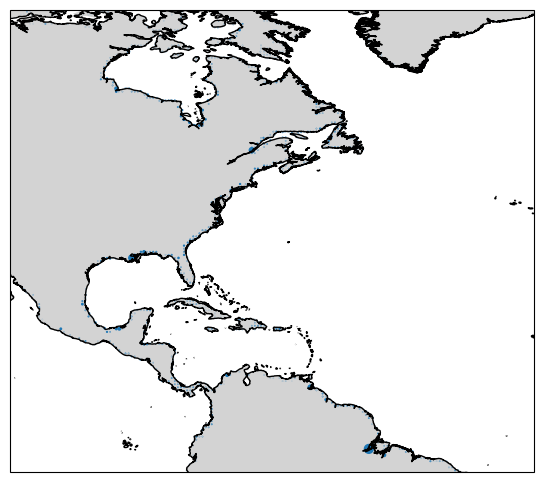

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy

# Choose a variable and time step to plot
data = river_nutrients['dic_riv_flux'].isel(time=0)
# Mask values <= 0
data_masked = data.where(data > 0)
lon_2d, lat_2d = np.meshgrid(data_masked.lon, data_masked.lat)

# Create a map plot
fig, ax = plt.subplots(figsize=(10,6), subplot_kw={'projection': ccrs.PlateCarree()})

# Plot data
ax.scatter(lon_2d,lat_2d, s=data_masked.load(), transform=ccrs.PlateCarree())

# Add coastlines and features
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
ax.coastlines(resolution='10m')  # looks better with resolution='10m'

# Set extent if desired (optional)
#ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())

plt.show()

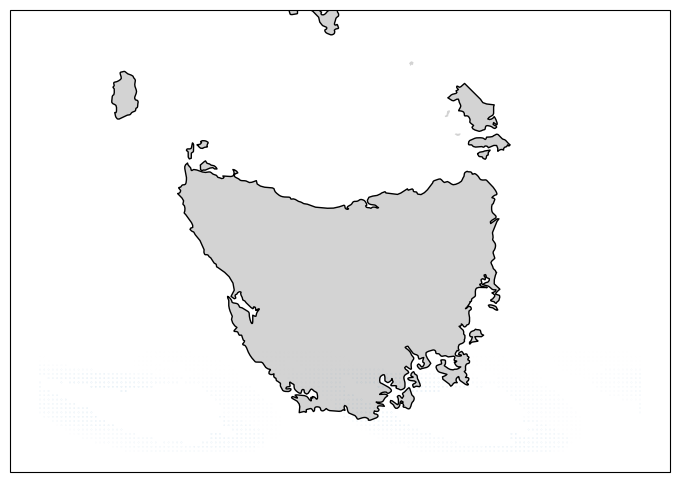

In [10]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy

# Choose a variable and time step to plot
data = river_nutrients_remapped['dic_riv_flux'].isel(time=0)
# Mask values <= 0
data_masked = data.where(data > 0)

# Create a map plot
fig, ax = plt.subplots(figsize=(10,6), subplot_kw={'projection': ccrs.PlateCarree()})

# Plot data
ax.scatter(tasman_grid_t_points.x,tasman_grid_t_points.y, s=data_masked.load()*100, transform=ccrs.PlateCarree())

# Add coastlines and features



ax.add_feature(cartopy.feature.LAND, fc='lightgray')
ax.coastlines(resolution='10m')  # looks better with resolution='10m'

# Set extent if desired (optional)
#ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())

plt.show()

In [24]:
np.where(~np.isnan(data_masked.load()*100))

(array([ 0,  0,  0, ..., 23, 23, 23]),
 array([ 20,  21,  22, ..., 135, 136, 137]))

In [ ]:
river_nutrients_remapped

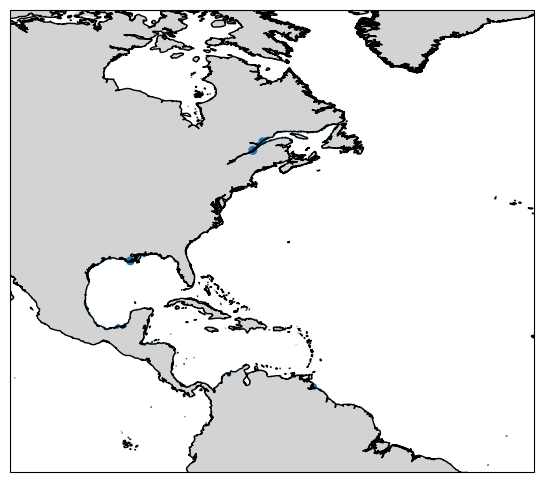

In [68]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy

# Choose a variable and time step to plot
data = river_nutrients_remapped_nn['dic_riv_flux'].isel(time=0)
# Mask values <= 0
data_masked = data.where(data > 0)

# Create a map plot
fig, ax = plt.subplots(figsize=(10,6), subplot_kw={'projection': ccrs.PlateCarree()})

# Plot data
ax.scatter(nwa_grid_t_points.x,nwa_grid_t_points.y, s=data_masked.load()*100, transform=ccrs.PlateCarree())

# Add coastlines and features



ax.add_feature(cartopy.feature.LAND, fc='lightgray')
ax.coastlines(resolution='10m')  # looks better with resolution='10m'

# Set extent if desired (optional)
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())

plt.show()

In [30]:
import xarray as xr
import cftime
import numpy as np

# new time value as cftime
new_time_val = cftime.DatetimeNoLeap(1900, 1, 1, 0, 0, 0)

# select only variables that have 'time' as a dimension
vars_with_time = [v for v in river_nutrients_remapped.data_vars if "time" in river_nutrients_remapped[v].dims]

# create new slice only for these
ref_slice_new = river_nutrients_remapped[vars_with_time].isel(time=0).expand_dims("time").copy()
ref_slice_new = ref_slice_new.assign_coords(time=[new_time_val])

# concatenate along time
river_nutrients_remapped_time_added = xr.concat(
    [ref_slice_new, river_nutrients_remapped[vars_with_time]],
    dim="time"
)

# assign the new time coordinate
river_nutrients_remapped_time_added = river_nutrients_remapped_time_added.assign_coords(
    time=np.concatenate([[new_time_val], river_nutrients_remapped["time"].values])
)

# combine back with variables that don’t have time
vars_without_time = [v for v in river_nutrients_remapped.data_vars if "time" not in river_nutrients_remapped[v].dims]
for v in vars_without_time:
    river_nutrients_remapped_time_added[v] = river_nutrients_remapped[v]


In [12]:
fill_value = -1e20
river_nutrients_remapped_nn.to_netcdf(
    "river_nutrients_remapped_nn.nc",
    encoding={var: {"_FillValue": fill_value} for var in river_nutrients_remapped_nn.data_vars}, unlimited_dims=["time"])


In [32]:

# add units to all data vars
for var in vars:
    river_nutrients_remapped_time_added[var].attrs["units"] = "mmol/cm^2/s"
time_units = "days since 0001-01-01 00:00:00"
time_calendar = "noleap"
time_num = cftime.date2num(
    river_nutrients_remapped_time_added["time"].values,
    units=time_units,
    calendar=time_calendar
)
river_nutrients_remapped_cleaned_temp = river_nutrients_remapped_time_added.rename_dims({
    "nx": "lon",
    "ny": "lat"
})

# replace time coordinate with float64 numeric values
river_nutrients_remapped_cleaned = river_nutrients_remapped_cleaned_temp.assign_coords(
    time=("time", np.array(time_num, dtype="float64"))
)


# force time to double, and set CF-compliant attrs
river_nutrients_remapped_cleaned["time"].attrs.update({
    "units": time_units,
    "calendar": "noleap",
    "long_name": "time",
})

# encoding only for data vars
encoding = {
    var: {"_FillValue": np.NaN} 
    for var in river_nutrients_remapped_cleaned.data_vars
}

fill_value = -1e20
river_nutrients_remapped_cleaned.to_netcdf(
    "river_nutrients_remapped_tasman_time_adj.nc",
    encoding=encoding, unlimited_dims=["time"])
